In [2]:
import pandas as pd
import numpy as np

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor 
from sklearn.pipeline import Pipeline

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
import zipfile
import requests
import os

# Pobieranie danych

In [5]:
def pobieranie_pliku(url, nazwa_csv, nazwa_zip):
    # Pobieranie danych
    r= requests.get(url, stream=True)
    r.raise_for_status()
    with open(nazwa_csv, 'wb') as f:
        for chunk in r.iter_content(chunk_size=10000):
            f.write(chunk)
    
    # Pakowanie pliku zip
    with zipfile.ZipFile(nazwa_zip, 'w', zipfile.ZIP_DEFLATED) as z:
        z.write(nazwa_csv)
    os.remove(nazwa_csv)


link:
https://github.com/xgabora/Club-Football-Match-Data-2000-2025

In [32]:
url = "https://raw.githubusercontent.com/xgabora/Club-Football-Match-Data-2000-2025/refs/heads/main/data/Matches.csv"
nazwa_csv= "mecze.csv"
nazwa_zip="mecze.zip"

pobieranie_pliku(url,nazwa_csv,nazwa_zip)

In [6]:
mecze = pd.read_csv("mecze.zip", compression='zip')
print(mecze)
mecze.columns

       Division   MatchDate MatchTime   HomeTeam    AwayTeam  HomeElo  \
0            F1  2000-07-28       NaN  Marseille      Troyes  1686.34   
1            F1  2000-07-28       NaN   Paris SG  Strasbourg  1714.89   
2            F2  2000-07-28       NaN  Wasquehal       Nancy  1465.08   
3            F1  2000-07-29       NaN    Auxerre       Sedan  1635.58   
4            F1  2000-07-29       NaN   Bordeaux        Metz  1734.34   
...         ...         ...       ...        ...         ...      ...   
230552      SP2  2025-06-01  17:30:00  Cartagena    Mirandes  1339.21   
230553      SP2  2025-06-01  17:30:00    Almeria    Tenerife  1544.16   
230554      SP2  2025-06-01  17:30:00  La Coruna       Elche  1473.67   
230555      SP2  2025-06-01  17:30:00     Oviedo       Cadiz  1574.90   
230556      SP2  2025-06-01  20:00:00    Cordoba    Albacete  1468.40   

        AwayElo  Form3Home  Form5Home  Form3Away  ...  MaxUnder25  HandiSize  \
0       1586.57        0.0        0.0      

C:\Users\MSI_GL72\AppData\Local\Temp\ipykernel_35292\728389304.py:1: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  mecze = pd.read_csv("mecze.zip", compression='zip')


Index(['Division', 'MatchDate', 'MatchTime', 'HomeTeam', 'AwayTeam', 'HomeElo',
       'AwayElo', 'Form3Home', 'Form5Home', 'Form3Away', 'Form5Away', 'FTHome',
       'FTAway', 'FTResult', 'HTHome', 'HTAway', 'HTResult', 'HomeShots',
       'AwayShots', 'HomeTarget', 'AwayTarget', 'HomeFouls', 'AwayFouls',
       'HomeCorners', 'AwayCorners', 'HomeYellow', 'AwayYellow', 'HomeRed',
       'AwayRed', 'OddHome', 'OddDraw', 'OddAway', 'MaxHome', 'MaxDraw',
       'MaxAway', 'Over25', 'Under25', 'MaxOver25', 'MaxUnder25', 'HandiSize',
       'HandiHome', 'HandiAway', 'C_LTH', 'C_LTA', 'C_VHD', 'C_VAD', 'C_HTB',
       'C_PHB'],
      dtype='object')

In [7]:
pd.set_option('display.max_columns', None)
mecze.head(100)

,Division,MatchDate,MatchTime,HomeTeam,AwayTeam,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,Form5Away,FTHome,FTAway,FTResult,HTHome,HTAway,HTResult,HomeShots,AwayShots,HomeTarget,AwayTarget,HomeFouls,AwayFouls,HomeCorners,AwayCorners,HomeYellow,AwayYellow,HomeRed,AwayRed,OddHome,OddDraw,OddAway,MaxHome,MaxDraw,MaxAway,Over25,Under25,MaxOver25,MaxUnder25,HandiSize,HandiHome,HandiAway,C_LTH,C_LTA,C_VHD,C_VAD,C_HTB,C_PHB
0,F1,2000-07-28,NaN,Marseille,Troyes,1686.34,1586.57,0.0,0.0,0.0,0.0,3.0,1.0,H,2.0,1.0,H,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.65,3.3,4.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,F1,2000-07-28,NaN,Paris SG,Strasbourg,1714.89,1642.51,0.0,0.0,0.0,0.0,3.0,1.0,H,1.0,1.0,D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.60,3.4,4.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,F2,2000-07-28,NaN,Wasquehal,Nancy,1465.08,1633.80,0.0,0.0,0.0,0.0,0.0,1.0,A,0.0,1.0,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,F1,2000-07-29,NaN,Auxerre,Sedan,1635.58,1624.22,0.0,0.0,0.0,0.0,0.0,1.0,A,0.0,1.0,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.70,3.3,3.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,F1,2000-07-29,NaN,Bordeaux,Metz,1734.34,1673.11,0.0,0.0,0.0,0.0,1.0,1.0,D,1.0,0.0,H,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.65,3.3,4.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,F2,2000-08-12,NaN,Nice,Lorient,1516.91,1484.23,6.0,10.0,2.0,3.0,1.0,1.0,D,1.0,1.0,D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
96,F2,2000-08-12,NaN,Nimes,Montpellier,1450.63,1614.09,3.0,5.0,9.0,15.0,0.0,2.0,A,0.0,1.0,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
97,F2,2000-08-12,NaN,Niort,Le Havre,1473.70,1579.15,5.0,8.0,6.0,10.0,1.0,1.0,D,1.0,0.0,H,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
98,F1,2000-08-13,NaN,Marseille,Lens,1691.36,1743.32,5.0,8.0,9.0,15.0,0.0,0.0,D,0.0,0.0,D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.71,3.5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
mecze.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 230557 entries, 0 to 230556
Data columns (total 48 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Division     230557 non-null  object 
 1   MatchDate    230557 non-null  object 
 2   MatchTime    99072 non-null   object 
 3   HomeTeam     230557 non-null  object 
 4   AwayTeam     230557 non-null  object 
 5   HomeElo      141597 non-null  float64
 6   AwayElo      141528 non-null  float64
 7   Form3Home    229057 non-null  float64
 8   Form5Home    229057 non-null  float64
 9   Form3Away    229057 non-null  float64
 10  Form5Away    229057 non-null  float64
 11  FTHome       230554 non-null  float64
 12  FTAway       230554 non-null  float64
 13  FTResult     230554 non-null  object 
 14  HTHome       175977 non-null  float64
 15  HTAway       175977 non-null  float64
 16  HTResult     175977 non-null  object 
 17  HomeShots    114735 non-null  float64
 18  AwayShots    114738 non-

In [9]:
mecze.describe()

,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,Form5Away,FTHome,FTAway,HTHome,HTAway,HomeShots,AwayShots,HomeTarget,AwayTarget,HomeFouls,AwayFouls,HomeCorners,AwayCorners,HomeYellow,AwayYellow,HomeRed,AwayRed,OddHome,OddDraw,OddAway,MaxHome,MaxDraw,MaxAway,Over25,Under25,MaxOver25,MaxUnder25,HandiSize,HandiHome,HandiAway,C_LTH,C_LTA,C_VHD,C_VAD,C_HTB,C_PHB
count,141597.000000,141528.000000,229057.000000,229057.000000,229057.000000,229057.000000,230554.000000,230554.000000,175977.000000,175977.000000,114735.000000,114738.000000,113929.000000,113932.000000,113973.000000,113973.000000,114363.000000,114363.000000,119298.000000,119299.000000,119299.000000,119297.00000,227527.000000,227527.000000,227527.000000,202922.000000,202922.000000,202922.000000,148398.000000,148397.000000,148398.000000,148397.000000,156733.000000,156475.000000,156451.000000,112602.000000,112602.000000,112602.000000,112602.000000,112602.000000,112602.000000
mean,1533.118663,1533.165652,3.984628,6.721606,4.203482,6.928241,1.488411,1.150646,0.657626,0.502782,12.769460,10.422075,5.113527,4.136318,12.604231,13.062594,5.656593,4.611526,1.683884,1.985800,0.086388,0.11686,2.461303,3.611563,4.018925,2.674641,3.875079,4.511122,1.944768,1.892438,2.045417,1.986764,-0.303375,1.919722,1.954644,0.216225,0.200979,0.146727,0.126160,0.173664,0.136246
std,153.279601,153.294511,2.377010,3.257166,2.393202,3.269548,1.258901,1.112735,0.812627,0.715419,4.999903,4.461799,2.761119,2.427446,4.468416,4.540744,2.940007,2.623002,1.307300,1.374269,0.297656,0.34610,1.373112,0.849323,2.647317,1.800707,1.101367,3.812976,0.277402,0.335539,0.538211,0.719088,0.729464,0.495534,0.351741,0.242283,0.239103,0.230572,0.216921,0.214677,0.199302
min,1103.130000,1103.130000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.290000,1.010000,1.020000,1.200000,0.000000,1.090000,1.200000,1.110000,1.260000,-99.900000,0.000000,-0.500000,0.009700,0.009700,0.009800,0.009700,0.009800,0.009700
25%,1424.870000,1424.930000,2.000000,4.000000,3.000000,4.000000,1.000000,0.000000,0.000000,0.000000,9.000000,7.000000,3.000000,2.000000,9.000000,10.000000,4.000000,3.000000,1.000000,1.000000,0.000000,0.00000,1.750000,3.210000,2.600000,1.850000,3.400000,2.720000,1.750000,1.670000,1.830000,1.750000,-0.500000,1.830000,1.830000,0.036000,0.032000,0.011400,0.010000,0.031100,0.021400
50%,1515.450000,1515.475000,4.000000,7.000000,4.000000,7.000000,1.000000,1.000000,0.000000,0.000000,12.000000,10.000000,5.000000,4.000000,12.000000,13.000000,5.000000,4.000000,2.000000,2.000000,0.000000,0.00000,2.150000,3.400000,3.330000,2.300000,3.600000,3.590000,1.940000,1.820000,2.040000,1.910000,-0.300000,1.920000,1.930000,0.102700,0.086300,0.036100,0.027100,0.073500,0.046800
75%,1634.240000,1634.222500,6.000000,9.000000,6.000000,9.000000,2.000000,2.000000,1.000000,1.000000,16.000000,13.000000,7.000000,6.000000,15.000000,16.000000,7.000000,6.000000,2.000000,3.000000,0.000000,0.00000,2.680000,3.710000,4.500000,2.880000,3.970000,5.000000,2.120000,2.020000,2.250000,2.120000,0.000000,2.010000,2.020000,0.325100,0.286100,0.154900,0.112600,0.225300,0.147000
max,2107.480000,2107.480000,9.000000,15.000000,9.000000,15.000000,10.000000,13.000000,7.000000,7.000000,46.000000,45.000000,31.000000,23.000000,145.000000,77.000000,26.000000,23.000000,11.000000,10.000000,3.000000,9.00000,53.180000,22.550000,71.710000,126.000000,47.000000,301.000000,3.950000,6.750000,172.000000,238.000000,12.500000,177.000000,15.140000,0.943700,0.944900,0.951200,0.951100,0.946500,0.941500


In [10]:
dane_do_wykresu= mecze.groupby('Division').agg(ilosc_meczy=("Division", "count")).reset_index()
print(dane_do_wykresu)

   Division  ilosc_meczy
0       ARG         5330
1       AUT         2306
2        B1         6559
3       BRA         4850
4       CHN         2544
5        D1         7522
6        D2         7161
7       DEN         2634
8        E0         9410
9        E1        13606
10       E2        13220
11       E3        12777
12       EC         7134
13       F1         8756
14       F2         8677
15      FIN         2354
16       G1         4128
17       I1         9012
18       I2         9921
19      IRL         2367
20      JAP         4089
21      MEX         4080
22       N1         7288
23      NOR         3092
24       P1         6626
25      POL         3567
26      ROM         3640
27      RUS         3008
28      SC0         5124
29      SC1         4094
30      SC2         4092
31      SC3         4010
32      SP1         9008
33      SP2        10497
34      SUI         2273
35      SWE         3110
36       T1         7458
37      USA         5233


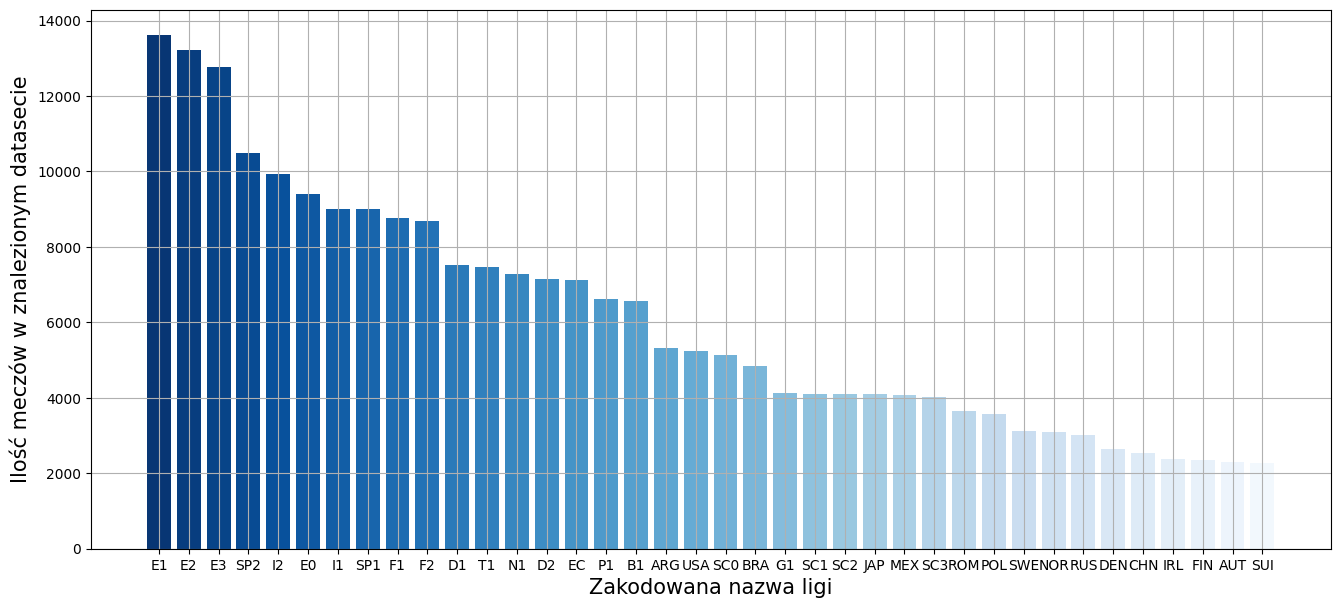

In [11]:
dane_posortowane = dane_do_wykresu.sort_values('ilosc_meczy', ascending=False).reset_index()


plt.figure(figsize=(16,7))
colors = sns.color_palette("Blues_r", len(dane_posortowane['ilosc_meczy']))
plt.bar(x=dane_posortowane['Division'], height= dane_posortowane['ilosc_meczy'], color = colors) 
plt.grid(True)
plt.xlabel("Zakodowana nazwa ligi", fontsize = 15)
plt.ylabel("Ilość meczów w znalezionym datasecie", fontsize = 15)
plt.show()

Tworzenie wektora zmiennej wynikowej y

In [12]:
print(mecze[mecze['FTResult'].isna()])

       Division   MatchDate MatchTime        HomeTeam     AwayTeam  HomeElo  \
112580       G1  2015-05-10       NaN      Niki Volos          OFI  1256.36   
130377      BRA  2016-11-12  19:00:00  Chapecoense-SC  Atletico-MG      NaN   
159189       G1  2019-03-17       NaN   Panathinaikos   Olympiakos  1440.16   

        AwayElo  Form3Home  Form5Home  Form3Away  Form5Away  FTHome  FTAway  \
112580  1276.54        0.0        0.0        0.0        0.0     NaN     NaN   
130377      NaN        NaN        NaN        NaN        NaN     NaN     NaN   
159189  1625.58        NaN        NaN        NaN        NaN     NaN     NaN   

       FTResult  HTHome  HTAway HTResult  HomeShots  AwayShots  HomeTarget  \
112580      NaN     NaN     NaN      NaN        NaN        NaN         NaN   
130377      NaN     NaN     NaN      NaN        NaN        NaN         NaN   
159189      NaN     0.0     3.0        A        NaN        NaN         NaN   

        AwayTarget  HomeFouls  AwayFouls  HomeCorners

In [13]:
mecze = mecze.dropna(subset=['FTResult']) # Usuwamy wiersze nie mające sensu, bo tu brakuje nam wektora wynikowego 

warunki = [mecze['FTHome'] > mecze['FTAway'], mecze['FTHome'] == mecze['FTAway'], mecze['FTHome'] < mecze['FTAway']]
wartosci= [0,1,2]
mecze['wynik'] = np.select(warunki, wartosci)


Wyrzucam zbędne kolumny, które doprowadziłyby do tzw. "data leakage", bo przed meczem nie śą nam znane statystyki pomeczowe

In [14]:
do_wywalenia = [
    'FTHome', 'FTAway', 'FTResult',               
    'HTHome', 'HTAway', 'HTResult',               
    'HomeShots', 'AwayShots', 'HomeTarget',       
    'AwayTarget', 'HomeFouls', 'AwayFouls', 
    'HomeCorners', 'AwayCorners', 'HomeYellow', 
    'AwayYellow', 'HomeRed', 'AwayRed',
    'C_LTH', 'C_LTA', 'C_VHD', 'C_VAD', 'C_HTB', 'C_PHB' # Klastry pomeczowe
]

mecze = mecze.drop(columns=do_wywalenia)

In [15]:
stats = mecze.select_dtypes(include='number').agg(['mean', 'std']).T.reset_index().rename(columns={'index': 'Nazwa_kolumny'})

In [16]:
print(stats)


   Nazwa_kolumny         mean         std
0        HomeElo  1533.121274  153.278720
1        AwayElo  1533.166812  153.293879
2      Form3Home     3.984646    2.377001
3      Form5Home     6.721636    3.257143
4      Form3Away     4.203500    2.393191
5      Form5Away     6.928271    3.269523
6        OddHome     2.461289    1.373105
7        OddDraw     3.611566    0.849326
8        OddAway     4.018941    2.647323
9        MaxHome     2.674627    1.800706
10       MaxDraw     3.875084    1.101371
11       MaxAway     4.511144    3.812988
12        Over25     1.944765    0.277401
13       Under25     1.892440    0.335539
14     MaxOver25     2.045414    0.538211
15    MaxUnder25     1.986767    0.719090
16     HandiSize    -0.303380    0.729463
17     HandiHome     1.919722    0.495536
18     HandiAway     1.954645    0.351741
19         wynik     0.842497    0.842669


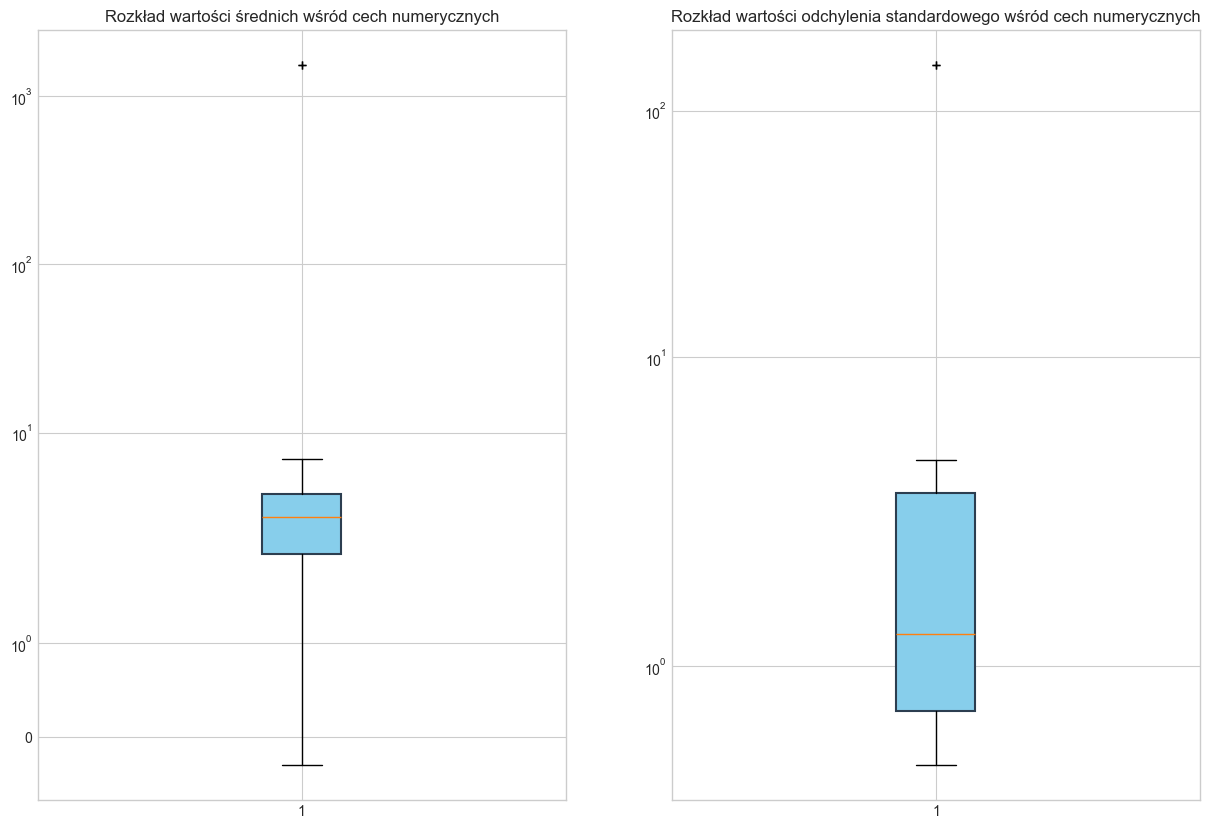

In [17]:
plt.style.use('seaborn-v0_8-whitegrid')
box_style = dict(facecolor='#87CEEB', color='#2C3E50', linewidth=1.5) # Jasnoniebieskie pudełko

fig, (plt1,plt2) = plt.subplots(1,2,figsize=(15,10))
plt1.boxplot(stats['mean'],patch_artist=True, boxprops= box_style, sym='+')
plt1.set_yscale('symlog')
plt1.set_title('Rozkład wartości średnich wśród cech numerycznych')
plt1.set_xlabel('')

plt2.boxplot(stats['std'],patch_artist=True, boxprops= box_style, sym='+')
plt2.set_yscale('symlog')
plt2.set_title('Rozkład wartości odchylenia standardowego wśród cech numerycznych')
plt2.set_xlabel('')
plt.show()


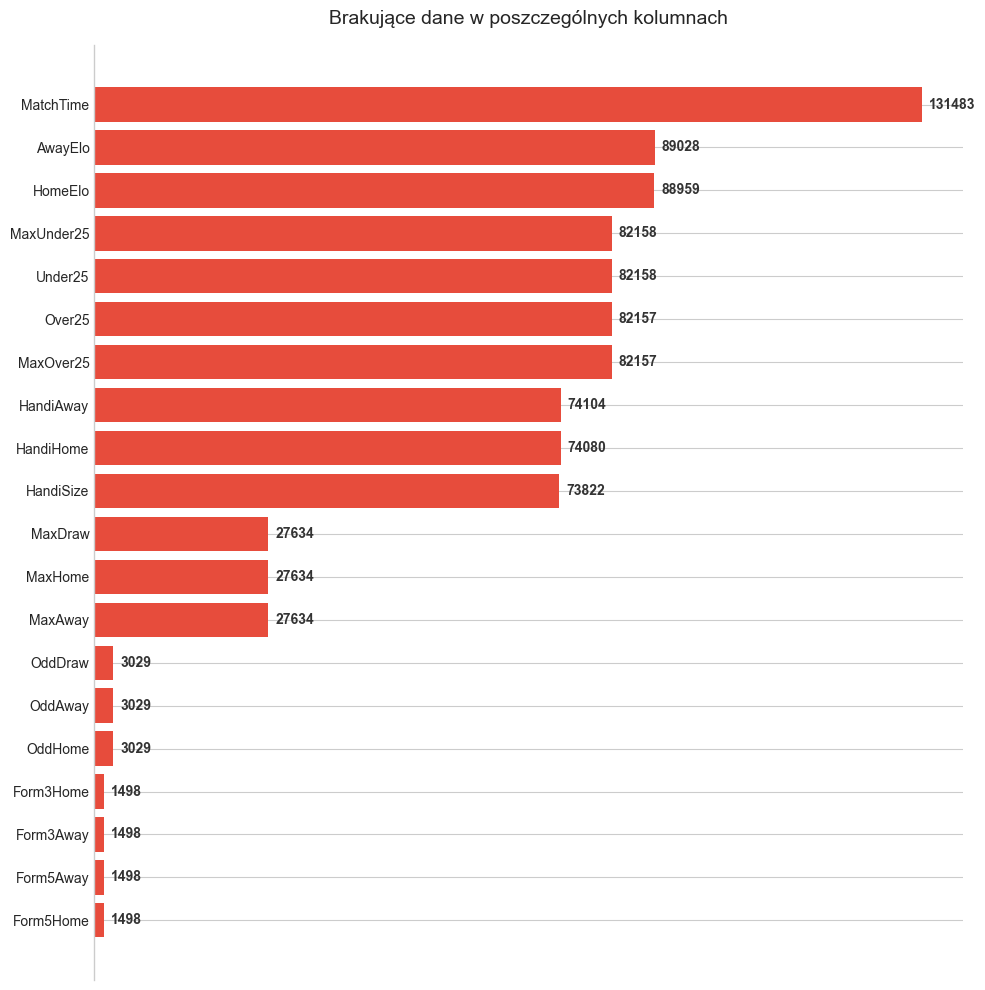

In [18]:
ilosc_na=mecze.loc[:,mecze.isna().sum() >0].isna().sum().reset_index()
ilosc_na.columns= ['nazwa', 'ilosc']
ilosc_na = ilosc_na.sort_values(by= 'ilosc', ascending=False)

fig, ax = plt.subplots(figsize=(10, 10))



wykres = ax.barh(y = ilosc_na['nazwa'], width=  ilosc_na['ilosc'], color='#E74C3C' )
ax.bar_label(wykres, padding=5, fontweight='bold', color='#333333')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_xticks([])
ax.invert_yaxis()

plt.title('Brakujące dane w poszczególnych kolumnach', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [30]:
mecze.tail(100)

,Division,MatchDate,MatchTime,HomeTeam,AwayTeam,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,Form5Away,OddHome,OddDraw,OddAway,MaxHome,MaxDraw,MaxAway,Over25,Under25,MaxOver25,MaxUnder25,HandiSize,HandiHome,HandiAway,wynik
230457,SP1,2025-05-18,18:00:00,Ath Madrid,Betis,1856.09,1765.54,4.0,7.0,5.0,11.0,1.95,3.72,3.69,2.09,3.93,3.85,1.76,2.08,1.82,2.15,-0.5,1.93,1.93,0
230458,SP1,2025-05-18,18:00:00,Barcelona,Villarreal,1946.63,1769.85,9.0,15.0,9.0,12.0,1.85,4.15,3.70,1.90,4.33,3.93,1.35,3.15,1.36,3.25,-0.5,1.85,2.00,2
230459,SP1,2025-05-18,18:00:00,Celta,Vallecano,1694.08,1651.11,6.0,9.0,7.0,8.0,1.78,3.91,4.32,1.83,4.02,4.60,1.74,2.10,1.81,2.17,-0.8,2.00,1.85,2
230460,SP1,2025-05-18,18:00:00,Las Palmas,Leganes,1583.07,1585.00,0.0,3.0,4.0,6.0,2.90,3.45,2.39,3.01,3.60,2.50,1.83,1.98,1.89,2.06,0.3,1.80,2.05,2
230461,SP1,2025-05-18,18:00:00,Mallorca,Getafe,1652.13,1634.54,3.0,4.0,0.0,0.0,2.01,3.20,4.16,2.10,3.31,4.33,2.67,1.46,2.75,1.49,-0.5,2.03,1.83,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
230552,SP2,2025-06-01,17:30:00,Cartagena,Mirandes,1339.21,1544.15,3.0,6.0,7.0,13.0,12.33,6.19,1.20,15.00,7.00,1.22,1.56,2.34,1.60,2.40,1.8,1.95,1.85,2
230553,SP2,2025-06-01,17:30:00,Almeria,Tenerife,1544.16,1433.67,4.0,10.0,1.0,3.0,1.22,6.23,10.97,1.24,6.75,13.00,1.51,2.41,1.55,2.55,-1.8,1.80,2.00,0
230554,SP2,2025-06-01,17:30:00,La Coruna,Elche,1473.67,1569.98,0.0,3.0,3.0,7.0,5.30,4.43,1.52,6.10,4.60,1.56,1.49,2.48,1.54,2.63,1.3,1.78,2.03,2
230555,SP2,2025-06-01,17:30:00,Oviedo,Cadiz,1574.90,1525.76,7.0,13.0,6.0,9.0,1.68,3.14,6.31,1.72,3.25,7.20,2.53,1.47,2.63,1.51,-0.8,1.95,1.85,0


# Podział na zbiór treningowy i testowy oraz preprocessing

In [19]:
X = mecze.drop(columns=['wynik'])
y = mecze['wynik']

In [20]:
def preprocessing_elo(df):

    df = df.sort_values('MatchDate').copy()

    # Imputacja elo dla gospodarzy
    df['HomeElo'] = df.groupby('HomeTeam')['HomeElo'].transform(
        lambda x: x.interpolate(method='linear', limit_direction='forward').ffill()
    )

    df['AwayElo'] = df.groupby('AwayTeam')['AwayElo'].transform(
        lambda x: x.interpolate(method = 'linear', limit_direction = 'forward').ffill()
    )

    return df

mecze_elo = preprocessing_elo(mecze)

In [33]:
print(mecze_elo[['AwayElo', 'HomeElo']].isna().sum())
print(mecze.groupby('Division')[['HomeElo', 'AwayElo', 'MatchTime', 'MaxHome', 'MaxDraw', 'MaxAway' ,'Over25', 'Under25', 'MaxOver25' , 'MaxUnder25' , 'HandiSize',	'HandiHome', 'HandiAway', 'MaxHome', 'MaxDraw',	'MaxAway']].apply(
    lambda x: x.isna().mean().round(2)
))

AwayElo    78531
HomeElo    78470
dtype: int64
          HomeElo  AwayElo  MatchTime  MaxHome  MaxDraw  MaxAway  Over25  \
Division                                                                   
ARG          1.00     1.00       0.00     0.00     0.00     0.00    1.00   
AUT          0.44     0.44       0.00     0.00     0.00     0.00    1.00   
B1           0.06     0.06       0.73     0.18     0.18     0.18    0.18   
BRA          1.00     1.00       0.00     0.00     0.00     0.00    1.00   
CHN          1.00     1.00       0.00     0.00     0.00     0.00    1.00   
D1           0.00     0.00       0.76     0.19     0.19     0.19    0.19   
D2           0.00     0.01       0.74     0.15     0.15     0.15    0.15   
DEN          0.24     0.24       0.00     0.00     0.00     0.00    1.00   
E0           0.00     0.00       0.76     0.19     0.19     0.19    0.19   
E1           0.01     0.01       0.76     0.19     0.19     0.19    0.19   
E2           0.88     0.88       0.76    

In [32]:
# 1. Obliczamy procent braków w kursach na Over 2.5 dla każdej ligi osobno
braki_w_ligach = mecze.groupby('Division')['Over25'].apply(lambda x: x.isna().mean())

# 2. Definiujemy dwa zbiory lig: 
# "Martwe" (powyżej 95% braków) i "Elitarne" (poniżej 95% braków)
ligi_do_usuniecia = braki_w_ligach[braki_w_ligach >= 0.95].index.tolist()
ligi_do_zachowania = braki_w_ligach[braki_w_ligach < 0.95].index.tolist()

# 3. Przeprowadzamy symulację na nowej, tymczasowej zmiennej
symulacja = mecze[mecze['Division'].isin(ligi_do_zachowania)]

# 4. Drukujemy raport dla Ciebie i Twojego promotora
print("=== RAPORT Z SYMULACJI CZYSZCZENIA DANYCH ===")
print(f"Początkowa liczba wszystkich meczów: {len(mecze)}")
print(f"Początkowa liczba wszystkich lig:  {mecze['Division'].nunique()}\n")

print(f"Ligi zidentyfikowane jako 'Martwe' (do usunięcia):")
print(ligi_do_usuniecia, "\n")

print("--- WYNIK OSTATECZNY ---")
print(f"Liczba wierszy po usunięciu śmieciowych lig: {len(symulacja)}")
print(f"Zostawiamy krystalicznie czystych lig:      {symulacja['Division'].nunique()}")
print(f"Całkowita liczba usuniętych meczów:          {len(mecze) - len(symulacja)}")

# Jeśli wynik Ci się podoba i chcesz to zatwierdzić, po prostu 
# odkomentuj linijkę poniżej i uruchom komórkę jeszcze raz:
# mecze = symulacja.copy()

=== RAPORT Z SYMULACJI CZYSZCZENIA DANYCH ===
Początkowa liczba wszystkich meczów: 230554
Początkowa liczba wszystkich lig:  38

Ligi zidentyfikowane jako 'Martwe' (do usunięcia):
['ARG', 'AUT', 'BRA', 'CHN', 'DEN', 'FIN', 'IRL', 'JAP', 'MEX', 'NOR', 'POL', 'ROM', 'RUS', 'SUI', 'SWE', 'USA'] 

--- WYNIK OSTATECZNY ---
Liczba wierszy po usunięciu śmieciowych lig: 176078
Zostawiamy krystalicznie czystych lig:      22
Całkowita liczba usuniętych meczów:          54476


to skopiownae nwm ocb z gemini

In [22]:
def oblicz_wlasne_elo(df, k_factor=20):
    df = df.sort_values('MatchDate').copy()
    aktualne_elo = {}
    home_elo_history = []
    away_elo_history = []
    
    for index, row in df.iterrows():
        home = row['HomeTeam']
        away = row['AwayTeam']
        wynik_meczu = row['wynik']  # Używamy Twojej zmiennej! (0, 1, 2)
        
        if home not in aktualne_elo: aktualne_elo[home] = 1500
        if away not in aktualne_elo: aktualne_elo[away] = 1500
            
        elo_h = aktualne_elo[home]
        elo_a = aktualne_elo[away]
        home_elo_history.append(elo_h)
        away_elo_history.append(elo_a)
        
        # Prawdopodobieństwo
        oczekiwane_h = 1 / (1 + 10 ** ((elo_a - elo_h) / 400))
        oczekiwane_a = 1 - oczekiwane_h
        
        # Przydział punktów na podstawie Twojej zmiennej 'wynik'
        if wynik_meczu == 0:     # Wygrana gospodarza
            punkty_h, punkty_a = 1, 0
        elif wynik_meczu == 2:   # Wygrana gości
            punkty_h, punkty_a = 0, 1
        else:                    # Remis (wynik_meczu == 1)
            punkty_h, punkty_a = 0.5, 0.5
            
        # Aktualizacja
        aktualne_elo[home] = elo_h + k_factor * (punkty_h - oczekiwane_h)
        aktualne_elo[away] = elo_a + k_factor * (punkty_a - oczekiwane_a)

    df['CustomHomeElo'] = np.round(home_elo_history, 2)
    df['CustomAwayElo'] = np.round(away_elo_history, 2)
    return df

mecze_elo_wlasne  = oblicz_wlasne_elo(mecze)

poprawic i dodac preproces dat i elo

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.1, shuffle= False) # Dodałem shuffle = False bo chce zrobić lagged featres do szeregu czasowego 

In [24]:
# Nazwy koilumn zawierających dane bukmacherskie
all_odds_cols = [
    'OddHome', 'OddDraw', 'OddAway', 'MaxHome', 'MaxDraw', 'MaxAway',
    'Over25', 'Under25', 'MaxOver25', 'MaxUnder25',
    'HandiSize', 'HandiHome', 'HandiAway'
]

# Kolumny z Elo i Formą
stats_cols = [
    'HomeElo', 'AwayElo', 
    'Form3Home', 'Form5Home', 'Form3Away', 'Form5Away'
]                           

# Cechy wyciągnięte z MatchDate i MatchTime (surowe daty zostaną usunięte)
date_features = ['DayOfWeek', 'Month', 'IsWeekend', 'MatchHour'] 

# Zmienne tekstowe do One-Hot-Encode
cat_cols = ['Division', 'HomeTeam', 'AwayTeam']

In [25]:
et_imputer = IterativeImputer(ExtraTreesRegressor(n_estimators=50, n_jobs=-1),max_iter=10)

odds_pipeline = Pipeline(steps=[
    ('imputer', et_imputer),
    ('scaler', StandardScaler())
])

stats_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

date_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='brak_danych')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('odds', odds_pipeline, all_odds_cols),
        ('stats', stats_pipeline, stats_cols),   
        ('date', date_pipeline, date_features),  
        ('cat', cat_pipeline, cat_cols)          
    ],
    remainder='drop' 
)